# 03 · Backtest: choosing the final model, then the untouched test

This notebook is the brief's backtest deliverable, built with **vectorbt**:

1. **Validation money test (2005–2020):** the 3 shortlisted models × 7 signal rules, backtested with costs against Buy & Hold
2. **Final pick:** model + Sell cut-off, chosen on excess return, yearly win rate and Sharpe (not on return alone), then frozen
3. **Test (2021 → latest), opened once:** the frozen recipe retrained each year; classification scores and the trading result
4. **The required chart:** portfolio value vs Buy & Hold
5. Per-year and per-quarter results, costs, and a monthly heatmap

**Backtest rules:**
- **Signal:** Sell if P(Sell) ≥ cut-off c; else Buy if P(Buy) is highest; else Hold.
- **Position:** all-in / all-out.
- **Timing:** signal at day t's close, trade at day t+1's open.
- **Costs:** fee 0.1% + slippage 0.05% per trade.
- **Cash:** earns 0%.
- **Dividends:** included through adjusted prices on days SPY is held.
- **Benchmark:** Buy & Hold over the same days, same costs.

In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from src.data import load_spy
from src.features import build_features, FEATURES
from src.labels import make_labels, CLASS_NAMES, CLASS_ORDER
from src.splits import walk_forward_folds
from src.models import run_walk_forward, always_buy_proba, classification_scores, block_bootstrap_ci, macro_f1
from src.backtest import evaluate, CUTOFFS, FEE, SLIPPAGE, INIT_CASH
from src import plotting as P

P.setup()
QUICK = os.environ.get("SPY_QUICK") == "1"
RES = ROOT / ("results_quick" if QUICK else "results")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
slug = lambda m: m.lower().replace(" ", "_").replace("-", "_")

px = load_spy()
data = build_features(px).join(make_labels(px["close"])).dropna()
X, y = data[FEATURES], data["label"].astype(int)
folds = walk_forward_folds(X.index)
val_folds = [f for f in folds if f.phase == "validate"]
test_folds = [f for f in folds if f.phase == "test"]
if QUICK:
    val_folds, test_folds = val_folds[-2:], test_folds[:2]
VAL_YEARS = [f.year for f in val_folds]
TEST_YEARS = [f.year for f in test_folds]

shortlist = json.load(open(RES / "shortlist.json"))["shortlist"]
val_proba = {m: pd.read_parquet(RES / f"val_proba_{slug(m)}.parquet") for m in shortlist}
print("Shortlist from notebook 02:", shortlist)

Shortlist from notebook 02: ['MLP', 'Random forest', 'Logistic regression']


## 1. Validation money test, 2005–2020

Each shortlisted model is run as **one continuous account** from 2005 to 2020, with 7 signal rules: the plain "highest probability wins" rule and Sell cut-offs c = 0.35 to 0.60. Every account is compared with Buy & Hold over the same days.

**Measures:**
- **Excess return:** model minus Buy & Hold, over the whole period.
- **Years won:** years with a higher return than Buy & Hold. A tie is a year the model was fully invested with no trades.
- **Median yearly Sharpe.**
- **Worst year:** the most negative yearly excess return.
- **Max drawdown, trades and costs.**

In [2]:
RULES = [None] + CUTOFFS
rule_name = lambda c: "highest prob." if c is None else f"c = {c:.2f}"
val_runs = {}
rows = []
for m in shortlist:
    for c in RULES:
        r = evaluate(px, val_proba[m], c, years=VAL_YEARS)
        val_runs[(m, c)] = r
        rows.append({"model": m, "rule": rule_name(c),
                     "excess return": r["excess total return"], "excess $": r["excess $"],
                     "years won": r["years won"], "years tied": r["years tied"],
                     "median yearly Sharpe": r["median yearly Sharpe"], "Sharpe": r["model"]["Sharpe"],
                     "worst year excess": r["worst year excess"], "max drawdown": r["model"]["max drawdown"],
                     "trades": r["model"]["trades"], "% time invested": r["model"]["% time invested"],
                     "costs $": r["model"]["costs paid $"]})
val_grid = pd.DataFrame(rows).set_index(["model", "rule"])
bh_val = next(iter(val_runs.values()))["bh_summary"]
print(f"Buy & Hold 2005–2020: total return {bh_val['total return']:.0%}, Sharpe {bh_val['Sharpe']:.2f}, "
      f"max drawdown {bh_val['max drawdown']:.0%}, end value ${bh_val['end value $']:,.0f}")
val_grid.style.format({"excess return": "{:+.0%}", "excess $": "{:+,.0f}", "median yearly Sharpe": "{:.2f}", "Sharpe": "{:.2f}",
                       "worst year excess": "{:+.0%}", "max drawdown": "{:.0%}", "% time invested": "{:.0%}", "costs $": "{:,.0f}"})

Buy & Hold 2005–2020: total return 321%, Sharpe 0.56, max drawdown -55%, end value $42,066


## 2. Final pick

1. **Cut-off per model:** the rule with the highest total excess return; ties go to the higher Sharpe. The plain "highest probability" rule competes too.
2. **Model:** rank the 3 (each with its best rule) on total excess return, years won and median yearly Sharpe, and add the ranks. The lowest total wins.
3. **Guard:** a candidate whose worst year trails Buy & Hold by more than 20 percentage points is dropped as a "disastrous worst year", unless all three fail it.
4. **Freeze:** the recipe (features, model, yearly tuning procedure, rule) is fixed before 2021 is opened.

In [3]:
best_rule = {}
for m in shortlist:
    g = val_grid.loc[m].sort_values(["excess return", "Sharpe"], ascending=False)
    best_rule[m] = g.index[0]
score = pd.DataFrame([{**val_grid.loc[(m, best_rule[m])].to_dict(), "model": m, "rule": best_rule[m],
                       "macro-F1 rank": k + 1} for k, m in enumerate(shortlist)]).set_index("model")
score["rank: excess return"] = score["excess return"].rank(ascending=False, method="min")
score["rank: years won"] = score["years won"].rank(ascending=False, method="min")
score["rank: median Sharpe"] = score["median yearly Sharpe"].rank(ascending=False, method="min")
score["rank total"] = score[["rank: excess return", "rank: years won", "rank: median Sharpe"]].sum(axis=1)
score["passes worst-year guard"] = score["worst year excess"] > -0.20
pool = score[score["passes worst-year guard"]] if score["passes worst-year guard"].any() else score
chosen = pool.sort_values(["rank total", "excess return"], ascending=[True, False]).index[0]
chosen_rule = best_rule[chosen]
chosen_c = None if chosen_rule == "highest prob." else float(chosen_rule.split("= ")[1])
score["picked"] = np.where(score.index == chosen, "✓", "")
print(f"FINAL RECIPE: {chosen}, rule '{chosen_rule}'")
json.dump({"model": chosen, "rule": chosen_rule, "cutoff": chosen_c}, open(RES / "final_recipe.json", "w"), indent=1)
score[["macro-F1 rank", "rule", "excess return", "excess $", "years won", "years tied", "median yearly Sharpe", "worst year excess",
       "max drawdown", "costs $", "rank total", "passes worst-year guard", "picked"]].style.format(
    {"excess return": "{:+.0%}", "excess $": "{:+,.0f}", "median yearly Sharpe": "{:.2f}", "worst year excess": "{:+.0%}",
     "max drawdown": "{:.0%}", "costs $": "{:,.0f}", "rank total": "{:.0f}"})

FINAL RECIPE: Logistic regression, rule 'c = 0.50'


,macro-F1 rank,rule,excess return,excess $,years won,years tied,median yearly Sharpe,worst year excess,max drawdown,costs $,rank total,passes worst-year guard,picked
model,,,,,,,,,,,,,
MLP,1,c = 0.50,+12%,"+1,198",6.000000,4.000000,1.18,-14%,-49%,"2,547",5,True,
Random forest,2,c = 0.55,+21%,"+2,140",2.000000,14.000000,0.90,-0%,-54%,154,8,True,
Logistic regression,3,c = 0.50,+159%,"+15,924",3.000000,11.000000,1.06,-8%,-42%,979,5,True,✓


### Return vs Buy & Hold per year, shortlist (each with its best rule)

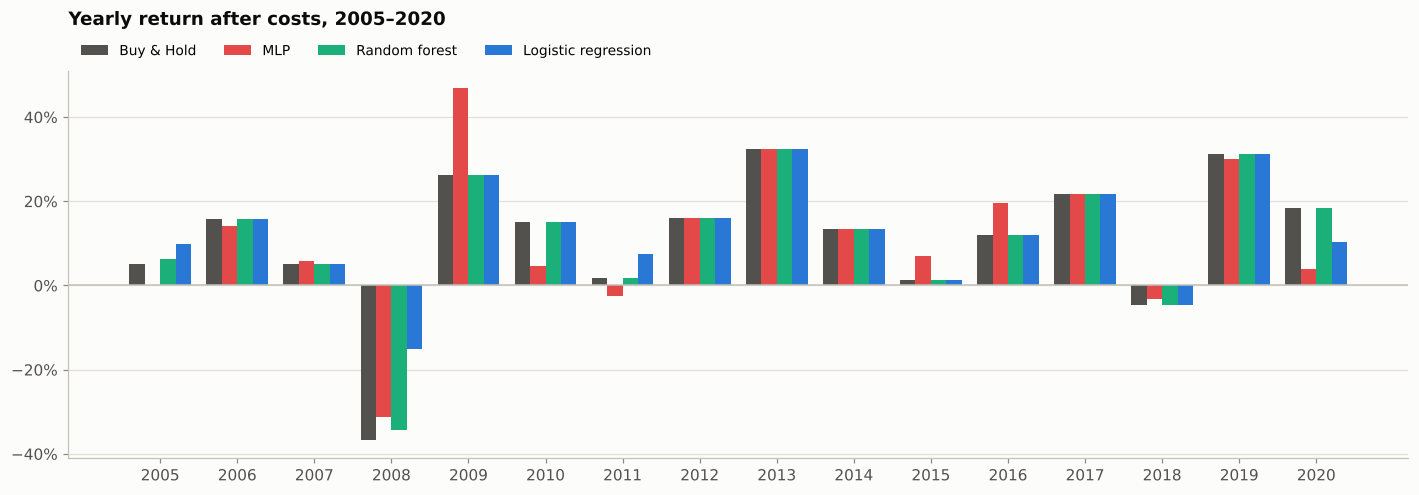

In [4]:
yrs = VAL_YEARS
fig, ax = plt.subplots(figsize=(13, 4.6))
w = 0.2
bh_year = val_runs[(shortlist[0], None)]["yearly"]["B&H return"]
series = [("Buy & Hold", bh_year)] + [(m, val_runs[(m, None if best_rule[m] == "highest prob." else float(best_rule[m].split('= ')[1]))]["yearly"]["model return"]) for m in shortlist]
for k, (name, s) in enumerate(series):
    ax.bar(np.arange(len(yrs)) + (k - 1.5) * w, s.reindex(yrs).values, width=w, color=P.MODEL_COLORS[name], label=name)
ax.axhline(0, color=P.AXIS, lw=1)
ax.set_xticks(range(len(yrs)), yrs); P.pct(ax); ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Yearly return after costs, 2005–2020", pad=30)
fig.tight_layout(); P.save(fig, "03_val_return_by_year")

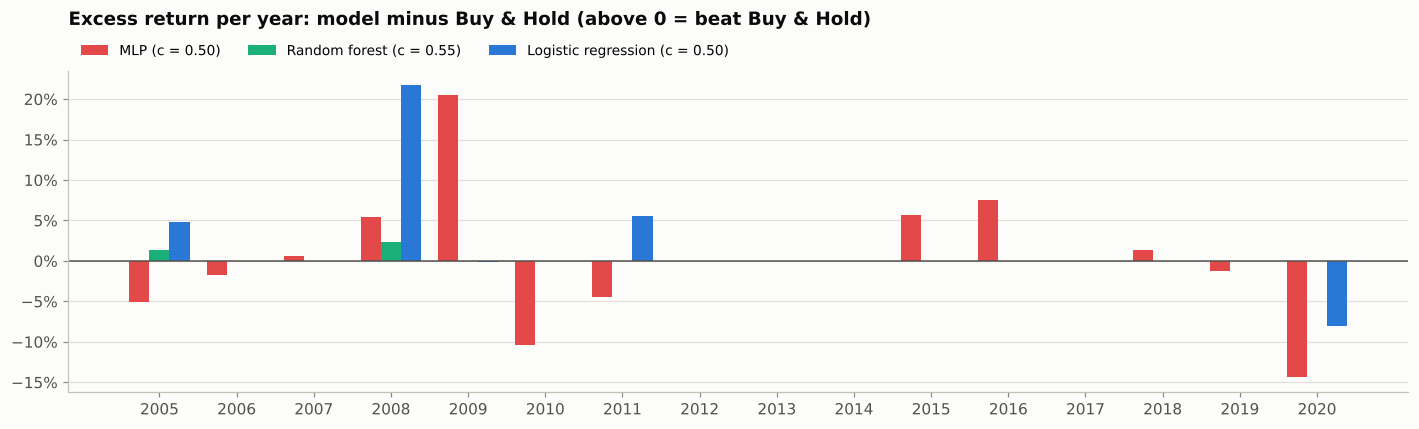

In [5]:
fig, ax = plt.subplots(figsize=(13, 4))
for k, m in enumerate(shortlist):
    c = None if best_rule[m] == "highest prob." else float(best_rule[m].split('= ')[1])
    ex = val_runs[(m, c)]["yearly"]["excess return"].reindex(yrs)
    ax.bar(np.arange(len(yrs)) + (k - 1) * 0.26, ex.values, width=0.26, color=P.MODEL_COLORS[m], label=f"{m} ({best_rule[m]})")
ax.axhline(0, color=P.INK2, lw=1)
ax.set_xticks(range(len(yrs)), yrs); P.pct(ax); ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Excess return per year: model minus Buy & Hold (above 0 = beat Buy & Hold)", pad=30)
fig.tight_layout(); P.save(fig, "03_val_excess_by_year")

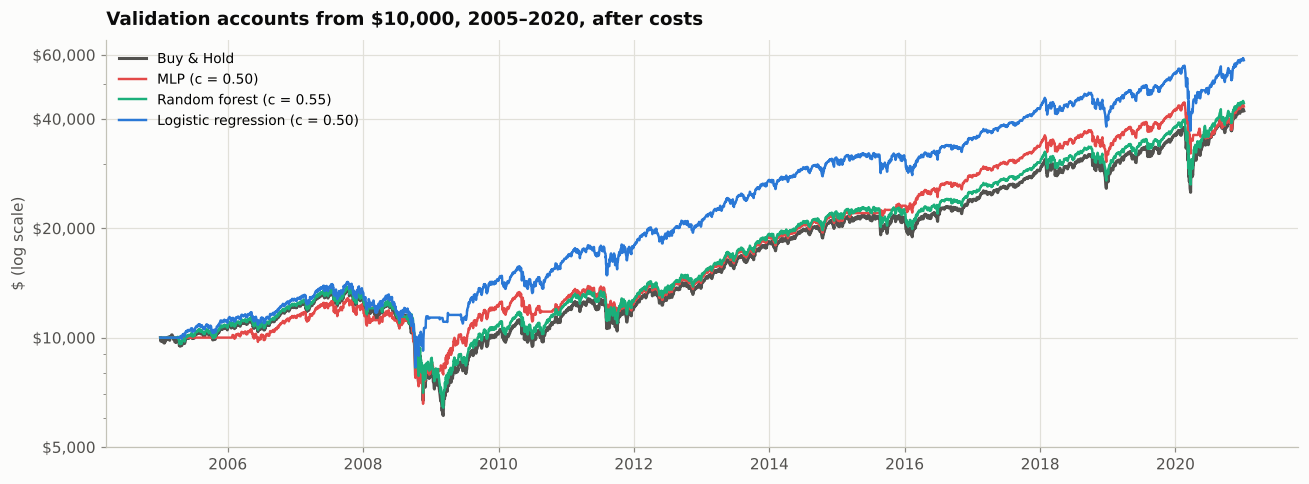

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
r0 = val_runs[(shortlist[0], None)]
ax.plot(r0["bh"].value(), color=P.BENCHMARK, lw=2, label="Buy & Hold")
for m in shortlist:
    c = None if best_rule[m] == "highest prob." else float(best_rule[m].split('= ')[1])
    ax.plot(val_runs[(m, c)]["pf"].value(), color=P.MODEL_COLORS[m], lw=1.6, label=f"{m} ({best_rule[m]})")
ax.set_yscale("log"); ax.set_ylabel("$ (log scale)")
ticks = [5000, 10000, 20000, 40000, 60000]
ax.set_yticks(ticks); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(loc="upper left"); ax.set_title("Validation accounts from $10,000, 2005–2020, after costs")
fig.tight_layout(); P.save(fig, "03_val_equity")

## 3. The untouched test, 2021 → latest

The frozen recipe is now run once on the test years. Each year it is **retrained and re-tuned** on all data before that year (5-row gap), exactly as in validation. The Dummy and "Always predict Buy" baselines are scored too.

In [7]:
test_proba = {}
for m in [chosen, "Dummy"]:
    pf_ = RES / f"test_proba_{slug(m)}.parquet"
    if pf_.exists():
        test_proba[m] = pd.read_parquet(pf_)
    else:
        p, log = run_walk_forward(m, X, y, test_folds, verbose=True)
        p.to_parquet(pf_); log.to_json(RES / f"test_log_{slug(m)}.json", indent=1)
        test_proba[m] = p
test_idx = np.concatenate([f.test_idx for f in test_folds])
test_proba["Always predict Buy"] = always_buy_proba(X.index[test_idx], X.index[test_idx].year)
y_test = y.iloc[test_idx]
print(f"Test rows: {len(y_test):,}, {y_test.index[0].date()} to {y_test.index[-1].date()}")

Test rows: 1,449, 2021-01-04 to 2026-10-09


### Classification scores on the test

In [8]:
from src.backtest import signals_from_proba
rows = []
preds = {"Dummy": test_proba["Dummy"]["pred"], "Always predict Buy": test_proba["Always predict Buy"]["pred"],
         chosen: test_proba[chosen]["pred"], f"{chosen} with {chosen_rule}": signals_from_proba(test_proba[chosen], chosen_c)}
for name, pr in preds.items():
    pr = pr.reindex(y_test.index)
    s = classification_scores(y_test, pr)
    lo, hi = block_bootstrap_ci(y_test.values, pr.values, macro_f1)
    rows.append({"model": name, **s, "macro_f1 95% CI": f"{lo:.3f} to {hi:.3f}"})
test_scores = pd.DataFrame(rows).set_index("model")
test_scores

,macro_f1,balanced_acc,accuracy,macro_f1 95% CI
model,,,,
Dummy,0.341,0.341,0.351,0.312 to 0.366
Always predict Buy,0.182,0.333,0.375,0.167 to 0.195
Logistic regression,0.399,0.406,0.427,0.366 to 0.432
Logistic regression with c = 0.50,0.313,0.369,0.427,0.287 to 0.336


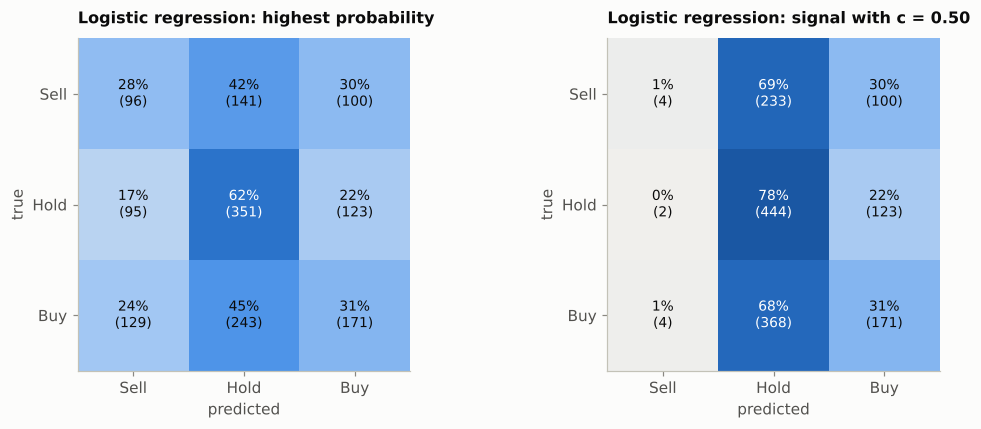

In [9]:
names = [CLASS_NAMES[c] for c in CLASS_ORDER]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, pr) in zip(axes, [(f"{chosen}: highest probability", test_proba[chosen]["pred"]),
                                  (f"{chosen}: signal with {chosen_rule}", signals_from_proba(test_proba[chosen], chosen_c))]):
    cm = confusion_matrix(y_test, pr.reindex(y_test.index), labels=CLASS_ORDER)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap=P.SEQUENTIAL, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=9, color="white" if cmn[i, j] > 0.55 else P.INK)
    ax.set_xticks(range(3), names); ax.set_yticks(range(3), names); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10.5)
fig.tight_layout(); P.save(fig, "03_test_confusion")

### Trading result on the test

In [10]:
test_run = evaluate(px, test_proba[chosen], chosen_c, years=TEST_YEARS)
test_sym = evaluate(px, test_proba[chosen], None, years=TEST_YEARS)
test_free = evaluate(px, test_proba[chosen], chosen_c, years=TEST_YEARS, fee=0.0, slippage=0.0)
sm, sb = test_run["model"], test_run["bh_summary"]
headline = pd.DataFrame({
    f"{chosen} ({chosen_rule})": sm, "Buy & Hold": sb,
    f"{chosen} (highest prob.)": test_sym["model"], f"{chosen} ({chosen_rule}), zero costs": test_free["model"],
}).T
headline.style.format({"start value $": "${:,.0f}", "end value $": "${:,.0f}", "total return": "{:+.1%}", "CAGR": "{:+.1%}",
                       "Sharpe": "{:.2f}", "max drawdown": "{:.1%}", "% time invested": "{:.0%}", "costs paid $": "${:,.0f}",
                       "costs % of start": "{:.2%}"})

,start value $,end value $,total return,CAGR,Sharpe,max drawdown,trades,% time invested,costs paid $,costs % of start
Logistic regression (c = 0.50),"$10,000","$21,272",+112.7%,+14.0%,0.88,-25.8%,7.000000,99%,$135,1.35%
Buy & Hold,"$10,000","$22,787",+127.9%,+15.3%,0.95,-24.5%,1.000000,100%,$15,0.15%
Logistic regression (highest prob.),"$10,000","$12,562",+25.6%,+4.0%,0.38,-25.1%,156.000000,56%,"$2,549",25.49%
"Logistic regression (c = 0.50), zero costs","$10,000","$21,497",+115.0%,+14.2%,0.89,-25.6%,7.000000,99%,$0,0.00%


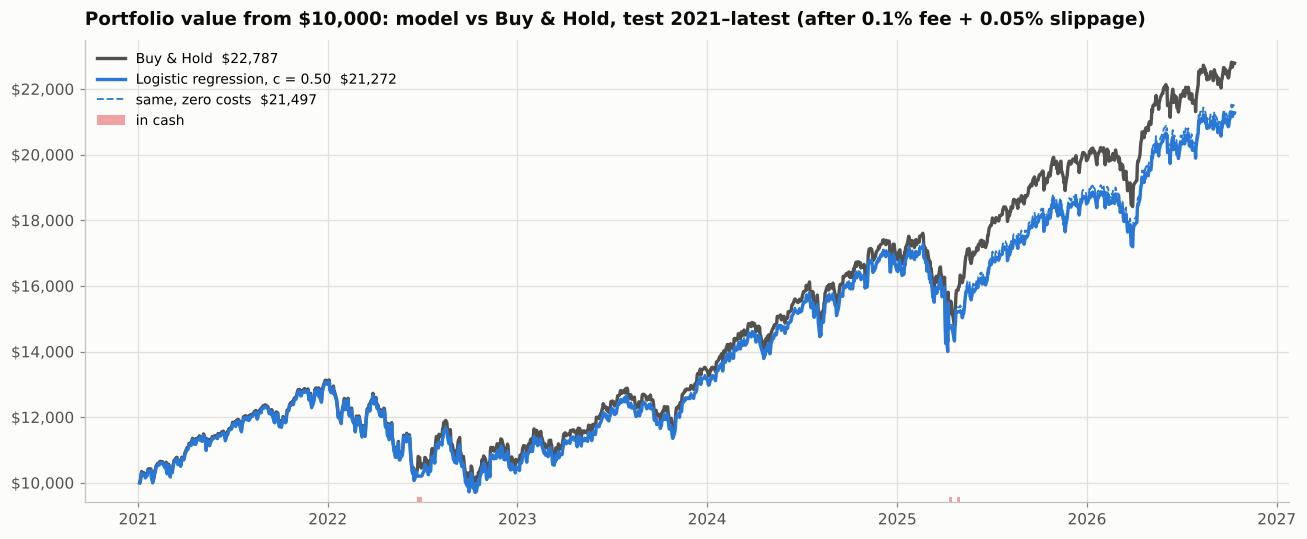

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test_run["bh"].value(), color=P.BENCHMARK, lw=2.2, label=f"Buy & Hold  ${sb['end value $']:,.0f}")
ax.plot(test_run["pf"].value(), color=P.MODEL_COLORS[chosen], lw=2.2, label=f"{chosen}, {chosen_rule}  ${sm['end value $']:,.0f}")
ax.plot(test_free["pf"].value(), color=P.MODEL_COLORS[chosen], lw=1.2, ls="--", label=f"same, zero costs  ${test_free['model']['end value $']:,.0f}")
inv = test_run["pf"].asset_value() > 0
ymin = min(test_run["pf"].value().min(), test_run["bh"].value().min()) * 0.97
ax.fill_between(inv.index, ymin, ymin * 1.015, where=~inv, color=P.CLASS_COLORS["Sell"], alpha=0.5, step="post", lw=0, label="in cash")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(loc="upper left"); ax.set_ylim(bottom=ymin)
ax.set_title(f"Portfolio value from $10,000: model vs Buy & Hold, test {TEST_YEARS[0]}–latest (after {FEE:.1%} fee + {SLIPPAGE:.2%} slippage)")
fig.tight_layout(); P.save(fig, "03_test_equity")

In [12]:
yt = test_run["yearly"][["model return", "B&H return", "excess return", "result", "model Sharpe", "B&H Sharpe", "trades", "% time invested"]]
yt.style.format({"model return": "{:+.1%}", "B&H return": "{:+.1%}", "excess return": "{:+.1%}", "model Sharpe": "{:.2f}",
                 "B&H Sharpe": "{:.2f}", "% time invested": "{:.0%}"})

,model return,B&H return,excess return,result,model Sharpe,B&H Sharpe,trades,% time invested
year,,,,,,,,
2021,+30.0%,+30.6%,-0.6%,loss,2.10,2.14,1,99%
2022,-19.6%,-18.2%,-1.4%,loss,-0.79,-0.71,2,97%
2023,+26.2%,+26.2%,+0.0%,tie,1.86,1.86,0,100%
2024,+24.9%,+24.9%,-0.0%,tie,1.83,1.83,0,100%
2025,+12.3%,+17.7%,-5.4%,loss,0.70,0.94,4,96%
2026,+15.0%,+15.0%,+0.0%,tie,1.46,1.46,0,100%


Years won: 0 of 6 (ties 3); quarters won: 1 of 24 (ties 20)


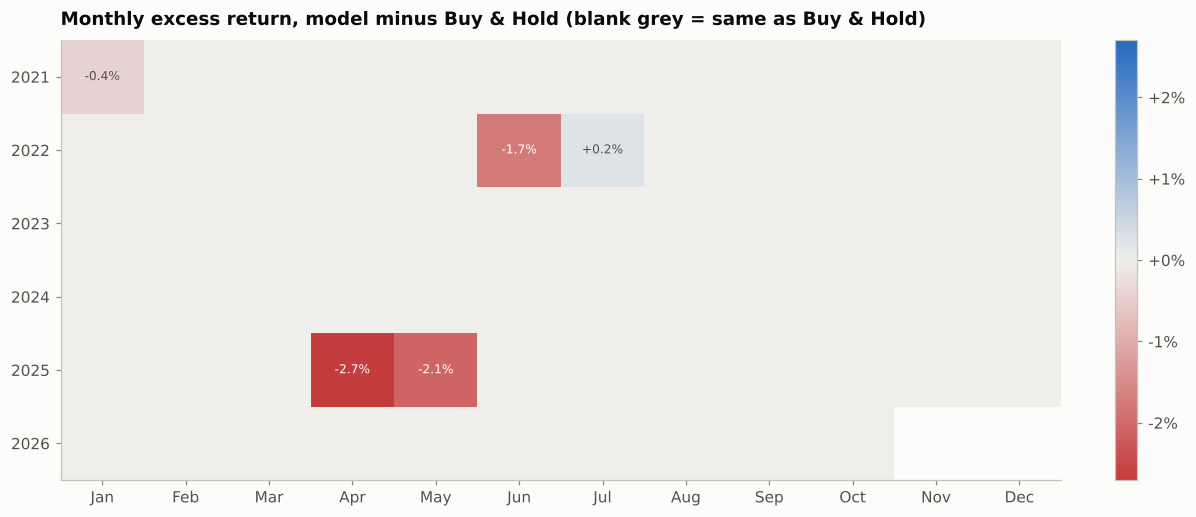

In [13]:
q = test_run["quarterly"]
print(f"Years won: {test_run['years won']} of {test_run['years']} (ties {test_run['years tied']}); "
      f"quarters won: {test_run['quarters won']} of {test_run['quarters']} (ties {test_run['quarters tied']})")
mv, bv = test_run["pf"].value(), test_run["bh"].value()
def month_ret(v):
    m = v.resample("ME").last()
    return m / pd.concat([pd.Series([v.iloc[0]]), m.iloc[:-1]]).set_axis(m.index) - 1  # first month starts from $10,000
monthly = month_ret(mv) - month_ret(bv)
heat = monthly.groupby([monthly.index.year, monthly.index.month]).first().unstack()
heat.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"][:heat.shape[1]] if heat.shape[1] == 12 else heat.columns
lim = max(0.02, np.nanmax(np.abs(heat.values)))
fig, ax = plt.subplots(figsize=(11, 0.6 * len(heat) + 1.2))
im = ax.imshow(heat.values, cmap=P.DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(len(heat)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        if pd.notna(v) and abs(v) >= 0.0005:
            ax.text(j, i, f"{v:+.1%}", ha="center", va="center", fontsize=8, color="white" if abs(v) > lim * 0.6 else P.INK2)
ax.grid(False); ax.set_title("Monthly excess return, model minus Buy & Hold (blank grey = same as Buy & Hold)")
fig.colorbar(im, ax=ax, fraction=0.03, format=plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
fig.tight_layout(); P.save(fig, "03_test_monthly_heatmap")

In [14]:
summary = {
    "data_last_date": str(px.index[-1].date()),
    "test_first_date": str(y_test.index[0].date()), "test_last_signal_date": str(y_test.index[-1].date()),
    "chosen_model": chosen, "rule": chosen_rule, "cutoff": chosen_c,
    "test_macro_f1": float(test_scores.loc[chosen, "macro_f1"]), "dummy_macro_f1": float(test_scores.loc["Dummy", "macro_f1"]),
    "test_accuracy": float(test_scores.loc[chosen, "accuracy"]),
    "model": {k: float(v) for k, v in sm.items()}, "buy_hold": {k: float(v) for k, v in sb.items()},
    "zero_cost_model": {k: float(v) for k, v in test_free["model"].items()},
    "symmetric_rule_model": {k: float(v) for k, v in test_sym["model"].items()},
    "excess_total_return": float(test_run["excess total return"]), "excess_dollars": float(test_run["excess $"]),
    "years_won": test_run["years won"], "years_tied": test_run["years tied"], "years": test_run["years"],
    "quarters_won": test_run["quarters won"], "quarters_tied": test_run["quarters tied"], "quarters": test_run["quarters"],
    "yearly": test_run["yearly"].reset_index().rename(columns={"index": "year"}).to_dict(orient="records"),
}
json.dump(summary, open(RES / "test_summary.json", "w"), indent=1, default=str)
print(json.dumps({k: v for k, v in summary.items() if k != "yearly"}, indent=1, default=str)[:1500])

{
 "data_last_date": "2026-10-16",
 "test_first_date": "2021-01-04",
 "test_last_signal_date": "2026-10-09",
 "chosen_model": "Logistic regression",
 "rule": "c = 0.50",
 "cutoff": 0.5,
 "test_macro_f1": 0.3985252216750958,
 "dummy_macro_f1": 0.34087620739168156,
 "test_accuracy": 0.42650103519668736,
 "model": {
  "start value $": 10000.0,
  "end value $": 21272.11135138853,
  "total return": 1.127211135138853,
  "CAGR": 0.1397935847870284,
  "Sharpe": 0.8789364042317522,
  "max drawdown": -0.2577599039013513,
  "trades": 7.0,
  "% time invested": 0.9868965517241379,
  "costs paid $": 135.39626789175634,
  "costs % of start": 0.013539626789175634
 },
 "buy_hold": {
  "start value $": 10000.0,
  "end value $": 22787.361546143216,
  "total return": 1.2787361546143217,
  "CAGR": 0.15347058912830835,
  "Sharpe": 0.9453756049776398,
  "max drawdown": -0.24496376908509887,
  "trades": 1.0,
  "% time invested": 0.9993103448275862,
  "costs paid $": 14.982518730643388,
  "costs % of start": 0

## Backtest findings

**Validation money test, 2005–2020** (Buy & Hold: +321%, Sharpe 0.56, worst drawdown −55%)

1. **The plain "highest probability wins" rule loses heavily for all three models.** It is in the market only about half the time, makes 300–380 trades, pays $4,000–8,000 in costs, and ends 156 to 315 percentage points behind Buy & Hold.
2. **The asymmetric Sell cut-off is what made money in validation.** With c = 0.50, logistic regression ended **$15,924 ahead of Buy & Hold (+159 points)**, with a smaller worst drawdown (−42% vs −55%). Most of that edge came from one event: it stepped out during the 2008 crash. Random forest (c = 0.55) and MLP (c = 0.50) beat Buy & Hold only slightly.
3. **Pick:** logistic regression with c = 0.50. It was best on total excess return and median yearly Sharpe (1.06), and its worst year trailed Buy & Hold by only 8 points.

**Untouched test, 2021 → Oct 2026**

4. **Prediction skill holds up.** Macro-F1 is 0.399 vs 0.341 for the dummy, with non-overlapping intervals. That is a little below validation (0.421), as expected out of sample.
5. **But the money edge does not.** The model ends at **$21,272 vs $22,787 for Buy & Hold (−15 points, −$1,515)**. Sharpe is 0.88 vs 0.95, and max drawdown −25.8% vs −24.5%. It won 0 of 6 years (3 lost, 3 tied) and 1 of 24 quarters (20 tied).
6. **The loss comes from timing, not costs.** The model was invested 98.7% of the time and made only 7 trades, so costs were just $135. The zero-cost version still ends below Buy & Hold. The damage came from three exits after drops, in June 2022 and April–May 2025, after which the market rebounded without the model.
7. **The plain rule is far worse on the test too:** $12,562, with 156 trades and $2,549 of costs.
8. **The validation win was flattered by selection.** It was picked as the best of 21 model-and-rule combinations, and it came mostly from a single crash. The test result is the honest estimate: the classifier has real but small skill, and that skill is not enough to beat Buy & Hold after costs.